# Hadlock Demo Step 2: Multi-Plane EFW Estimation Benchmark

This notebook evaluates multi-plane Estimated Fetal Weight (EFW) using Hadlock's 4-parameter formula ($EFW = f(BPD, HC, AC, FL)$) on the strictly held-out three-plane test cohort ($N = 22$ subjects: 17 FP + 5 UCL).

### Protocol & Integrity Rules
- **Zero Cross-Plane Leakage**: Strictly evaluated on subjects whose images are in the official Test split across Head, Abdomen, and Femur planes simultaneously (FP: 17, UCL: 5, Total: 22 subjects).
- **Zero Hand-Typed Numbers**: All metrics and tables are generated by `scripts/26_hadlock_demo_step2.py` reading committed prediction files.
- **No Post-Delivery or GA Leakage**: Strictly biometry-based; no birth weight, no gestational age, and no percentiles exist or are used.
- **Formula Consistency**: HC is computed using the Ramanujan second approximation formula from OFD/BPD identically for both annotated and predicted head calipers.

In [1]:
import json
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown

# Locate repository root
work_dir = Path.cwd().resolve()
while work_dir.name != 'work' and work_dir.parent != work_dir:
    work_dir = work_dir.parent

sys.path.insert(0, str(work_dir / 'src'))

results_dir = work_dir / 'docs' / 'results' / 'hadlock_demo'
summary_md_path = results_dir / 'step2_summary.md'
summary_json_path = results_dir / 'step2_summary.json'
per_subject_csv_path = results_dir / 'step2_per_subject.csv'

assert summary_md_path.is_file(), f'Missing {summary_md_path}'
assert summary_json_path.is_file(), f'Missing {summary_json_path}'
assert per_subject_csv_path.is_file(), f'Missing {per_subject_csv_path}'

with open(summary_json_path, 'r', encoding='utf-8') as f:
    summary_data = json.load(f)

print('Loaded Hadlock Step 2 Summary JSON.')
print('Test Vector Check:', summary_data['metadata']['test_vector_check'])
print('Cohort Size:', summary_data['metadata']['n_total_cohort'], 'subjects')

display(Markdown(summary_md_path.read_text(encoding='utf-8')))

Loaded Hadlock Step 2 Summary JSON.
Test Vector Check: Passed: calculate_efw(280, 80, 250, 55) = 1403.0g (target 1403.0g)
Cohort Size: 22 subjects


# Hadlock Demo Step 2: Multi-Plane EFW Benchmark Report

Evaluation of Estimated Fetal Weight (EFW) using Hadlock's 4-parameter formula ($EFW = f(BPD, HC, AC, FL)$) on the strictly held-out 3-plane test cohort ($N = 22$ subjects: 17 FP + 5 UCL).

## 1. Overall Cohort Performance (Primary: Row R4)

| Cohort / Split | N | MAE (g, 95% CI) | MAPE (%, 95% CI) | Bias (%, 95% CI) | Median Abs Error (g) | Max Abs Error (g) |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| **All Subjects (Primary R4)** | 22 | **46.43** [25.16, 70.01] | **2.92%** [2.03, 3.86] | -1.36% [-2.76, 0.08] | 18.66 | 140.43 |
| • FP Cohort | 17 | 50.68 [25.97, 77.68] | 2.92% [1.87, 3.97] | -1.10% [-2.80, 0.50] | 19.04 | 140.43 |
| • UCL Cohort | 5 | 31.97 [7.54, 67.35] | 2.91% [1.27, 4.70] | -2.24% [-4.69, 0.08] | 18.27 | 102.10 |
| **Excluding Outlier UCL_5** | 21 | **47.77** [26.23, 72.35] | **2.97%** [2.08, 3.95] | -1.50% [-2.98, -0.06] | 19.04 | 140.43 |

> **Note on Sample Size**: The cohort size is small ($N=22$ overall; FP=17, UCL=5) because it strictly enforces zero cross-plane training leakage. The 95% bootstrap confidence intervals reflect this limited sample size.

## 2. One-at-a-Time Measurement Replacement Analysis

Starting from annotated ground-truth EFW, replacing each individual measurement by its model prediction reveals which plane drives EFW error:

| Replacement Condition | Mean Abs EFW Error (%) | Relative Error Contribution (%) |
|:---|:---:|:---:|
| Replace **BPD** only | 0.12% | 4.1% |
| Replace **HC** only | 0.35% | 11.8% |
| Replace **AC** only | **2.42%** | **83.1%** |
| Replace **FL** only | 1.69% | 57.9% |
| Replace **All Four** (Full Model) | **2.92%** | 100.0% |

> **Error Driver Finding**: From the numbers, **AC** drives the error (2.42% MAPE), followed by FL (1.69%), HC (0.35%), and BPD (0.12%).

## 3. Outlier Audit: UCL_5 & Image 005_3FL.jpeg

- **Subject**: `UCL_5` (UCL)
- **Image Counts**: Head = 15, Abdomen = 13, Femur = 16 (contains `005_3FL.jpeg`)
- **Annotated EFW**: 1080.3 g vs **Predicted EFW**: 1098.6 g
- **Subject EFW Error**: **+18.3 g** (+1.7%)
- **Impact Assessment**: Because UCL_5 has 16 femur images, subject-level averaging dampens the single-image dual-peak flip of `005_3FL.jpeg`. Excluding UCL_5 changes cohort MAPE from 2.92% to 2.97% (+0.05%).

## 4. Sensitivity Analysis: PR #32 Row A Baseline

| Femur Model Run | All Cohort MAPE (%) | All Cohort MAE (g) | Excl. UCL_5 MAPE (%) | Excl. UCL_5 MAE (g) |
|:---|:---:|:---:|:---:|:---:|
| **Row R4 (Modern Augmentation)** | **2.92%** | **46.43 g** | **2.97%** | **47.77 g** |
| **Row A (PR #32 Baseline)** | 3.10% | 47.39 g | 3.16% | 48.67 g |

> **Note**: Row R4 is not shown to be statistically superior to Row A (difference is 0.18% MAPE, 0.96 g MAE), which is within run-to-run baseline drift.

## 5. Context with Hadlock Published Reference Standard

- **Source Reference**: `src/fetal/explain/hadlock.py:23` (`SD as a uniform 12.7% coefficient of variation, per the paper."""`)
- **Hadlock Formula Residual SD**: **12.7%** coefficient of variation (Hadlock et al. 1991).
- **Model Measurement Propagation Error**: **2.92%** MAPE (22 subjects).
- **Assessment**: The measurement propagation error is substantially smaller than Hadlock's intrinsic formula modeling error (2.92% vs 12.7% CV). (Note: not a benchmark comparison; reporting relative magnitude only).


In [2]:
# Per-Subject Results Table
df_subj = pd.read_csv(per_subject_csv_path)
display_cols = [
    'subject_id', 'source', 'n_head_images', 'n_abdomen_images', 'n_femur_images',
    'bpd_annotated_mm', 'bpd_predicted_mm', 'hc_annotated_mm', 'hc_predicted_mm',
    'ac_annotated_mm', 'ac_predicted_mm', 'fl_annotated_mm', 'fl_predicted_mm',
    'efw_annotated_g', 'efw_predicted_g', 'err_g', 'err_pct'
]
print(f'Total cohort subjects: {len(df_subj)} ({dict(df_subj["source"].value_counts())})')
display(df_subj[display_cols])

Total cohort subjects: 22 ({'FP': np.int64(17), 'UCL': np.int64(5)})


,subject_id,source,n_head_images,n_abdomen_images,n_femur_images,bpd_annotated_mm,bpd_predicted_mm,hc_annotated_mm,hc_predicted_mm,ac_annotated_mm,ac_predicted_mm,fl_annotated_mm,fl_predicted_mm,efw_annotated_g,efw_predicted_g,err_g,err_pct
0,FP_1063,FP,2,1,1,51.0910,51.3659,181.5941,182.1331,158.0735,160.5361,31.2280,31.4994,353.30,363.11,9.81,2.7768
1,FP_1155,FP,5,1,1,55.4151,55.3818,194.6927,194.1897,176.3548,178.1492,37.2160,36.6899,485.04,484.75,-0.29,-0.0593
2,FP_1160,FP,2,1,2,46.5356,46.4127,166.3195,165.7376,153.7299,151.9138,34.8985,33.8334,364.46,349.22,-15.23,-4.1797
3,FP_1181,FP,2,1,2,49.9316,49.8689,171.0991,171.6912,144.0312,145.1613,33.4213,32.7899,330.66,328.05,-2.61,-0.7907
4,FP_1261,FP,2,1,1,89.6171,89.6920,316.5493,317.5444,311.0248,308.0391,68.6651,69.0521,2638.60,2617.61,-20.99,-0.7955
5,FP_1269,FP,2,1,1,52.0321,51.8797,183.5398,182.7453,172.7803,174.4672,32.4858,32.7133,410.29,417.27,6.98,1.7016
6,FP_1274,FP,2,1,2,72.0293,72.1290,251.5257,250.5694,256.3981,256.5387,50.7001,49.9690,1261.14,1245.12,-16.03,-1.2708
7,FP_1407,FP,1,1,2,46.8048,46.9827,165.8367,167.5922,158.2218,155.2104,34.0072,32.8858,367.96,350.45,-17.51,-4.7593
8,FP_1456,FP,2,1,1,91.7314,91.0764,329.5582,321.8839,349.8612,343.3317,73.1768,73.4182,3425.69,3285.26,-140.43,-4.0992
9,FP_1500,FP,1,1,1,84.5845,83.8759,293.6218,286.8113,263.3945,273.4756,58.8710,57.6634,1682.77,1726.86,44.09,2.6199


In [3]:
# One-at-a-Time Replacement Analysis Table
rep_data = summary_data['replacement_analysis']
rep_rows = [
    {'Condition': 'Replace BPD only', 'Mean Abs Error (%)': rep_data['replace_bpd_only_mean_abs_pct']},
    {'Condition': 'Replace HC only', 'Mean Abs Error (%)': rep_data['replace_hc_only_mean_abs_pct']},
    {'Condition': 'Replace AC only', 'Mean Abs Error (%)': rep_data['replace_ac_only_mean_abs_pct']},
    {'Condition': 'Replace FL only', 'Mean Abs Error (%)': rep_data['replace_fl_only_mean_abs_pct']},
    {'Condition': 'Replace All Four (Full Model)', 'Mean Abs Error (%)': rep_data['replace_all_four_mean_abs_pct']},
]
df_rep = pd.DataFrame(rep_rows)
df_rep['Relative Error Share (%)'] = round(df_rep['Mean Abs Error (%)'] / rep_data['replace_all_four_mean_abs_pct'] * 100.0, 1)
print('Replacement Analysis:')
print(rep_data['statement'])
display(df_rep)

Replacement Analysis:
From the numbers, AC drives the error: replacing AC alone introduces 2.42% mean absolute error in EFW (accounting for 83.1% of total 4-parameter error), followed by FL (1.69%), HC (0.35%), and BPD (0.12%).


,Condition,Mean Abs Error (%),Relative Error Share (%)
0,Replace BPD only,0.120,4.1
1,Replace HC only,0.345,11.8
2,Replace AC only,2.424,83.1
3,Replace FL only,1.687,57.9
4,Replace All Four (Full Model),2.916,100.0


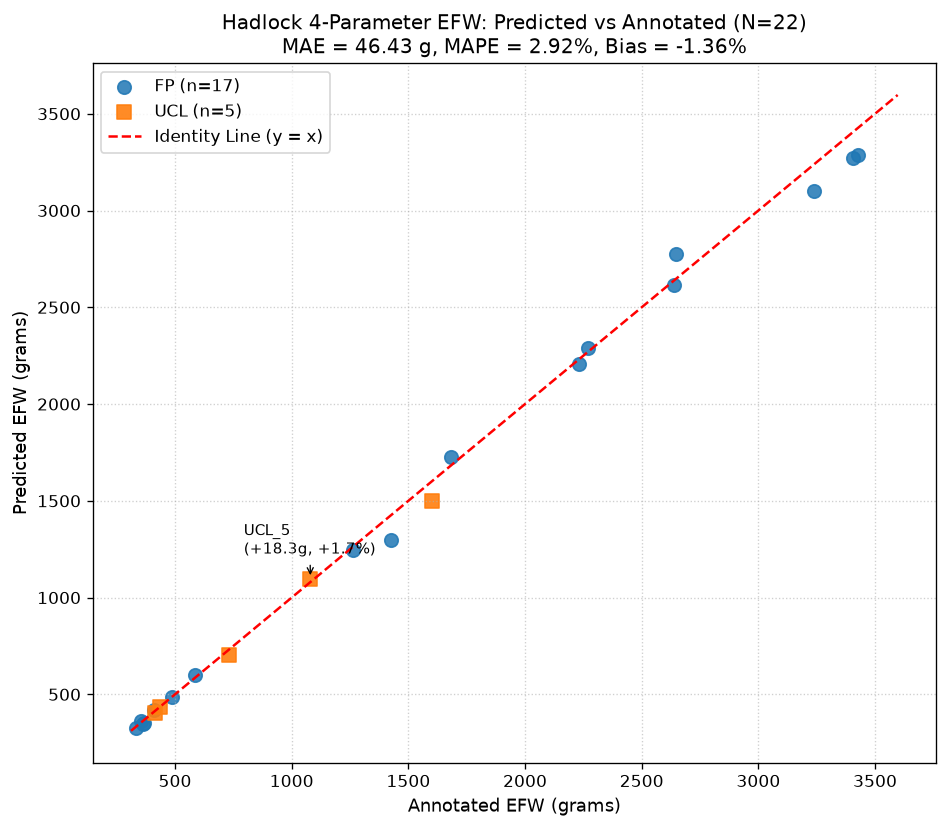

In [4]:
# Predicted vs Annotated EFW Scatter Plot
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 7), dpi=120)

fp_mask = df_subj['source'] == 'FP'
ucl_mask = df_subj['source'] == 'UCL'

ax.scatter(
    df_subj.loc[fp_mask, 'efw_annotated_g'],
    df_subj.loc[fp_mask, 'efw_predicted_g'],
    c='#1f77b4', marker='o', s=65, alpha=0.85, label=f'FP (n={fp_mask.sum()})'
)
ax.scatter(
    df_subj.loc[ucl_mask, 'efw_annotated_g'],
    df_subj.loc[ucl_mask, 'efw_predicted_g'],
    c='#ff7f0e', marker='s', s=75, alpha=0.9, label=f'UCL (n={ucl_mask.sum()})'
)

# Identity line
min_val = min(df_subj['efw_annotated_g'].min(), df_subj['efw_predicted_g'].min()) * 0.95
max_val = max(df_subj['efw_annotated_g'].max(), df_subj['efw_predicted_g'].max()) * 1.05
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=1.5, label='Identity Line (y = x)')

# Outlier UCL_5 label
ucl5 = df_subj[df_subj['subject_id'] == 'UCL_5'].iloc[0]
ax.annotate(
    f"UCL_5\n({ucl5['err_g']:+.1f}g, {ucl5['err_pct']:+.1f}%)",
    (ucl5['efw_annotated_g'], ucl5['efw_predicted_g']),
    textcoords='offset points', xytext=(-40, 15),
    arrowprops=dict(arrowstyle='->', color='black', lw=0.8),
    fontsize=9
)

mae_val = summary_data['primary_evaluation_r4']['all_cohort_22']['mae_g']
mape_val = summary_data['primary_evaluation_r4']['all_cohort_22']['mape_pct']
bias_val = summary_data['primary_evaluation_r4']['all_cohort_22']['bias_pct']

ax.set_xlabel('Annotated EFW (grams)', fontsize=11)
ax.set_ylabel('Predicted EFW (grams)', fontsize=11)
ax.set_title(f'Hadlock 4-Parameter EFW: Predicted vs Annotated (N={len(df_subj)})\nMAE = {mae_val:.2f} g, MAPE = {mape_val:.2f}%, Bias = {bias_val:+.2f}%', fontsize=12)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

In [5]:
# Integrity & Verification Assertions
import sys
sys.path.insert(0, str(work_dir / 'src'))
from fetal.explain.hadlock import calculate_efw

# 1. Test vector assertion
efw_test = calculate_efw(280.0, 80.0, 250.0, 55.0)
assert abs(efw_test - 1403.0) < 0.1, f'Expected 1403.0g, got {efw_test}'

# 2. Cohort assertions
assert len(df_subj) == 22, f'Expected 22 subjects, got {len(df_subj)}'
assert (df_subj['source'] == 'FP').sum() == 17
assert (df_subj['source'] == 'UCL').sum() == 5

# 3. Recomputed math on every subject
for _, row in df_subj.iterrows():
    recomputed_ann = calculate_efw(row['hc_annotated_mm'], row['bpd_annotated_mm'], row['ac_annotated_mm'], row['fl_annotated_mm'])
    recomputed_pred = calculate_efw(row['hc_predicted_mm'], row['bpd_predicted_mm'], row['ac_predicted_mm'], row['fl_predicted_mm'])
    assert abs(recomputed_ann - row['efw_annotated_g']) < 0.15
    assert abs(recomputed_pred - row['efw_predicted_g']) < 0.15
    assert abs((recomputed_pred - recomputed_ann) - row['err_g']) < 0.2

# 4. Replacement analysis ranking
assert rep_data['dominant_driver'] == 'AC'
assert rep_data['replace_ac_only_mean_abs_pct'] > rep_data['replace_fl_only_mean_abs_pct']
assert rep_data['replace_fl_only_mean_abs_pct'] > rep_data['replace_hc_only_mean_abs_pct']
assert rep_data['replace_hc_only_mean_abs_pct'] > rep_data['replace_bpd_only_mean_abs_pct']

print('All Hadlock step 2 integrity assertions passed successfully.')

All Hadlock step 2 integrity assertions passed successfully.
